**Импорт библиотек и настройка**

In [1]:
import os
import time
import copy
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

import torchvision
import torchvision.transforms as transforms
from torchvision import models

import matplotlib.pyplot as plt
import numpy as np

from torchmetrics.classification import MulticlassF1Score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Устройство: cuda


**Загрузка и подготовка данных**

In [2]:
DATA_DIR = Path("Downloads/Garbage classification/Garbage classification")

# Трансформации
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Полный датасет
full_dataset = torchvision.datasets.ImageFolder(root=DATA_DIR, transform=None)

CLASS_NAMES = full_dataset.classes
NUM_CLASSES = len(CLASS_NAMES)
print(f"Классы ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"Всего изображений: {len(full_dataset)}")
print(f"Форма одного изображения (исходная): {full_dataset[0][0].size}")

Классы (6): ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Всего изображений: 2527
Форма одного изображения (исходная): (512, 384)


Разделение 70/15/15

In [3]:
total_size = len(full_dataset)
train_size = int(0.70 * total_size)
val_size   = int(0.15 * total_size)
test_size  = total_size - train_size - val_size

train_subset, val_subset, test_subset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print(f"Train: {len(train_subset)} | Val: {len(val_subset)} | Test: {len(test_subset)}")

Train: 1768 | Val: 379 | Test: 380


Создаём датасеты с нужными трансформациями

In [4]:
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, idx):
        img, label = self.subset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset   = TransformedSubset(val_subset, val_test_transform)
test_dataset  = TransformedSubset(test_subset, val_test_transform)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

Визуализация примеров

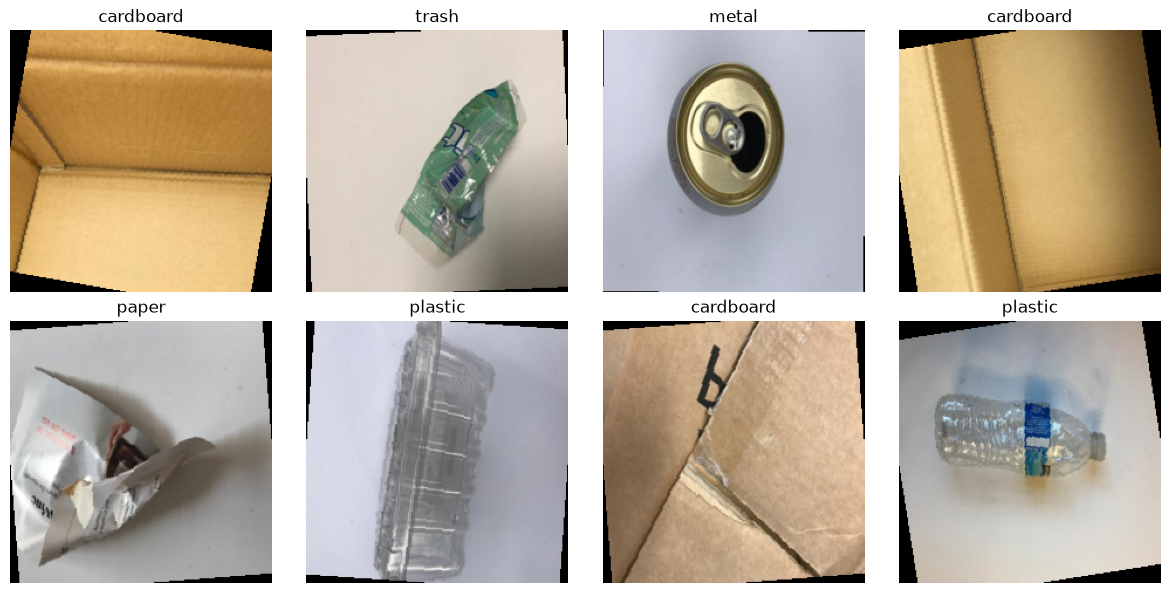

In [5]:
def imshow(img_tensor):
    img = img_tensor.numpy().transpose((1, 2, 0))
    img = np.array([0.229, 0.224, 0.225]) * img + np.array([0.485, 0.456, 0.406])
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, idx in zip(axes.flat, np.random.choice(len(train_dataset), 8, replace=False)):
    img, label = train_dataset[idx]
    ax.imshow(imshow(img))
    ax.set_title(CLASS_NAMES[label])
    ax.axis("off")
plt.tight_layout()
plt.show()

Подготовка четырёх моделей

In [6]:
def get_model(name, pretrained=False, num_classes=NUM_CLASSES):
    """Возвращает модель с заменённой головой под нашу задачу."""
    if name == "resnet18":
        model = models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == "efficientnet_b0":
        model = models.efficientnet_b0(weights="IMAGENET1K_V1" if pretrained else None)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
    elif name == "mobilenet_v2":
        model = models.mobilenet_v2(weights="IMAGENET1K_V1" if pretrained else None)
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
    elif name == "vit_b_16":
        model = models.vit_b_16(weights="IMAGENET1K_V1" if pretrained else None)
        in_features = model.heads.head.in_features
        model.heads.head = nn.Linear(in_features, num_classes)
    else:
        raise ValueError(f"Неизвестная модель: {name}")
    return model

MODEL_NAMES = ["resnet18", "efficientnet_b0", "mobilenet_v2", "vit_b_16"]

Для переноса знаний замораживаем backbone и обучаем только новый классификатор — это классический и быстрый вариант feature extraction.

In [7]:
def freeze_backbone(model, name):
    """Замораживает все слои, кроме финального классификатора."""
    for param in model.parameters():
        param.requires_grad = False

    if name == "resnet18":
        for param in model.fc.parameters():
            param.requires_grad = True
    elif name in ("efficientnet_b0", "mobilenet_v2"):
        for param in model.classifier.parameters():
            param.requires_grad = True
    elif name == "vit_b_16":
        for param in model.heads.parameters():
            param.requires_grad = True

**Функции обучения и оценки**

In [8]:
def train_one_epoch(model, loader, criterion, optimizer, device, freeze_bn=False):
    model.train()
    if freeze_bn:
        for m in model.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()

    running_loss = 0.0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader, device):
    """Возвращает (loss, macro_f1)."""
    model.eval()
    criterion = nn.CrossEntropyLoss()
    running_loss = 0.0
    f1_metric = MulticlassF1Score(num_classes=NUM_CLASSES, average="macro").to(device)  # [reference:2]

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        f1_metric.update(outputs, labels)

    avg_loss = running_loss / len(loader.dataset)
    macro_f1 = f1_metric.compute().item()
    return avg_loss, macro_f1


def train_model(model, train_loader, val_loader, device, epochs=15, lr=1e-3, freeze_bn=False):
    """Обучает модель, возвращает историю val Macro F1 по эпохам."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = {"val_f1": []}

    for epoch in range(1, epochs + 1):
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device, freeze_bn=freeze_bn)
        val_loss, val_f1 = evaluate(model, val_loader, device)
        history["val_f1"].append(val_f1)
        scheduler.step()
        print(f"  Эпоха {epoch:2d}/{epochs} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f} | val Macro F1: {val_f1:.4f}")

    return history

**Запуск 8 экспериментов**

In [9]:
EPOCHS = 15
results = {}          # (model_name, experiment_type) -> test_macro_f1
histories = {}        # (model_name, experiment_type) -> history

for name in MODEL_NAMES:
    for pretrained in [False, True]:
        exp_type = "pretrained" if pretrained else "scratch"
        key = (name, exp_type)
        print(f"\n{'='*60}")
        print(f"Модель: {name} | Эксперимент: {exp_type}")
        print(f"{'='*60}")

        model = get_model(name, pretrained=pretrained).to(device)

        if pretrained:
            freeze_backbone(model, name)
            lr = 1e-3
        else:
            lr = 1e-3

        history = train_model(
                                model, train_loader, val_loader, device,
                                epochs=EPOCHS, lr=lr,
                                freeze_bn=(exp_type == "pretrained")   # ← BN в eval только для переноса
                            )
        histories[key] = history

        # Оценка на тесте
        test_loss, test_f1 = evaluate(model, test_loader, device)
        results[key] = test_f1
        print(f"  >>> TEST Macro F1: {test_f1:.4f}")


Модель: resnet18 | Эксперимент: scratch
  Эпоха  1/15 | train loss: 1.5105 | val loss: 1.7322 | val Macro F1: 0.3100
  Эпоха  2/15 | train loss: 1.2855 | val loss: 1.3302 | val Macro F1: 0.4191
  Эпоха  3/15 | train loss: 1.1921 | val loss: 2.7574 | val Macro F1: 0.3911
  Эпоха  4/15 | train loss: 1.1815 | val loss: 1.2103 | val Macro F1: 0.4865
  Эпоха  5/15 | train loss: 1.1316 | val loss: 1.2366 | val Macro F1: 0.5095
  Эпоха  6/15 | train loss: 1.0452 | val loss: 1.1798 | val Macro F1: 0.5692
  Эпоха  7/15 | train loss: 1.0117 | val loss: 1.0863 | val Macro F1: 0.5811
  Эпоха  8/15 | train loss: 0.9307 | val loss: 1.1108 | val Macro F1: 0.5915
  Эпоха  9/15 | train loss: 0.8572 | val loss: 1.1572 | val Macro F1: 0.6005
  Эпоха 10/15 | train loss: 0.8084 | val loss: 0.7939 | val Macro F1: 0.6908
  Эпоха 11/15 | train loss: 0.7324 | val loss: 1.0903 | val Macro F1: 0.5738
  Эпоха 12/15 | train loss: 0.6652 | val loss: 0.9966 | val Macro F1: 0.6436
  Эпоха 13/15 | train loss: 0.6171 

**График Macro F1 на валидации**

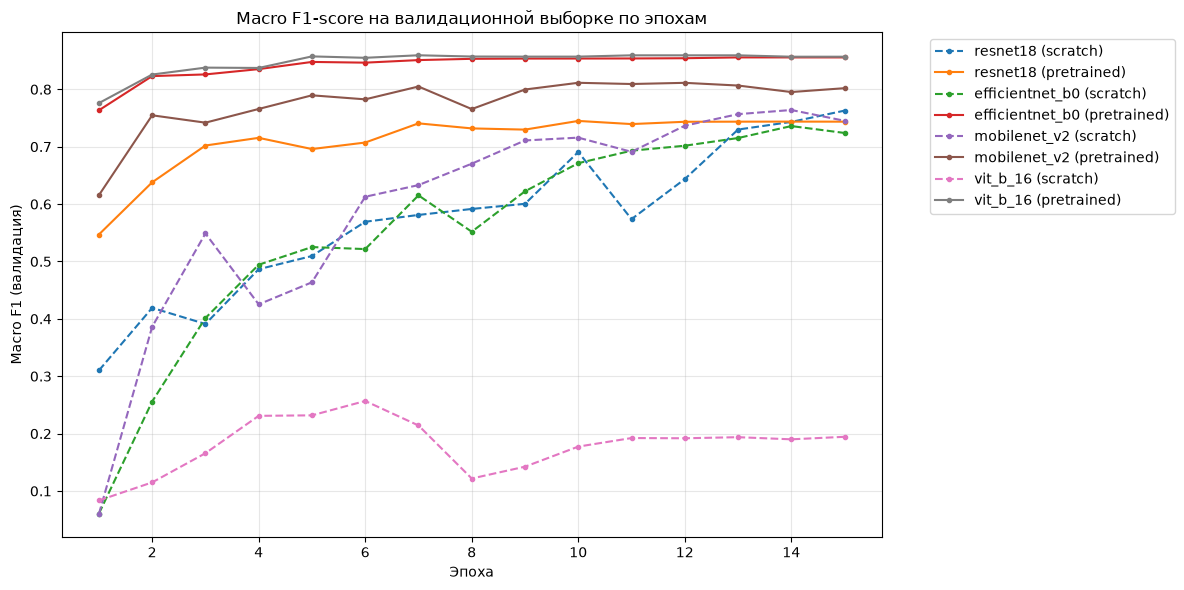

In [10]:
plt.figure(figsize=(12, 6))
epochs_range = range(1, EPOCHS + 1)

for (name, exp_type), hist in histories.items():
    style = "-" if exp_type == "pretrained" else "--"
    plt.plot(epochs_range, hist["val_f1"], style, marker="o", markersize=3,
             label=f"{name} ({exp_type})")

plt.xlabel("Эпоха")
plt.ylabel("Macro F1 (валидация)")
plt.title("Macro F1-score на валидационной выборке по эпохам")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

 Сравнительная столбчатая диаграмма

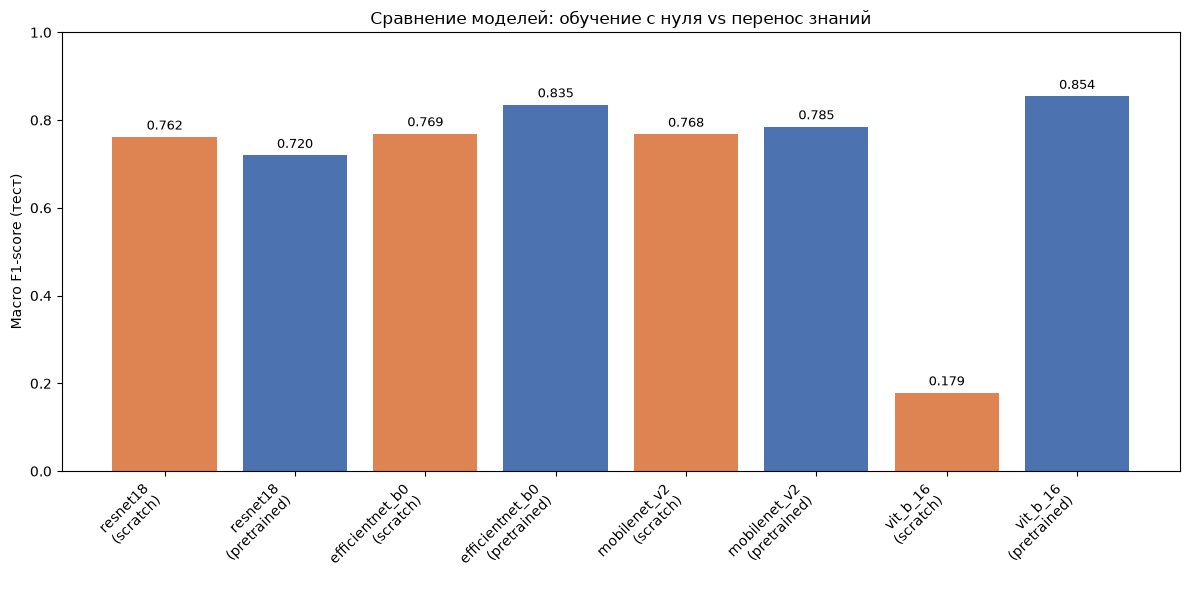

In [11]:
labels = [f"{name}\n({exp})" for (name, exp) in results.keys()]
values = list(results.values())
colors = ["#4C72B0" if "pretrained" in label else "#DD8452" for label in labels]

plt.figure(figsize=(12, 6))
bars = plt.bar(labels, values, color=colors)
plt.ylim(0, 1.0)
plt.ylabel("Macro F1-score (тест)")
plt.title("Сравнение моделей: обучение с нуля vs перенос знаний")
plt.xticks(rotation=45, ha="right")

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 0.01, f"{v:.3f}",
             ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

**Итоговая таблица**

In [12]:
print(f"\n{'Модель':<20} {'Эксперимент':<15} {'Test Macro F1':>15}")
print("-" * 55)
for (name, exp), f1 in sorted(results.items(), key=lambda x: -x[1]):
    print(f"{name:<20} {exp:<15} {f1:>15.4f}")


Модель               Эксперимент       Test Macro F1
-------------------------------------------------------
vit_b_16             pretrained               0.8543
efficientnet_b0      pretrained               0.8350
mobilenet_v2         pretrained               0.7850
efficientnet_b0      scratch                  0.7691
mobilenet_v2         scratch                  0.7680
resnet18             scratch                  0.7615
resnet18             pretrained               0.7197
vit_b_16             scratch                  0.1786
